In [ ]:
# ============================================================
# LOAD CIC-IDS2017 CSV FILES
# ============================================================

import pandas as pd
import glob
import os

csv_files = glob.glob("/content/*.csv")

print("CSV files found:", len(csv_files))

dataframes = []

for file in csv_files:
    print("Loading:", os.path.basename(file))
    dataframes.append(pd.read_csv(file))

df = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

CSV files found: 8
Loading: Botnet-Friday-no-metadata.csv
Loading: DDoS-Friday-no-metadata.csv
Loading: WebAttacks-Thursday-no-metadata.csv
Loading: Bruteforce-Tuesday-no-metadata.csv
Loading: DoS-Wednesday-no-metadata.csv
Loading: Benign-Monday-no-metadata.csv
Loading: Infiltration-Thursday-no-metadata.csv
Loading: Portscan-Friday-no-metadata.csv

Dataset loaded successfully!
Rows: 2313810
Columns: 78


## 1. Problem Definition

In [ ]:
# ============================================================
# 1. PROBLEM DEFINITION
# ============================================================

print("Network Intrusion Detection")
print("Detect normal and malicious network traffic")
print("Algorithms: Random Forest and Gradient-Boosted Trees")

Network Intrusion Detection
Detect normal and malicious network traffic
Algorithms: Random Forest and Gradient-Boosted Trees


## 2. Dataset Collection

In [ ]:
# ============================================================
# 2. DATASET COLLECTION
# ============================================================

import pandas as pd
import glob
import os

csv_files = glob.glob("/content/*.csv")

print("CSV files found:", len(csv_files))

dataframes = []

for file in csv_files:
    print("Loading:", os.path.basename(file))
    dataframes.append(pd.read_csv(file))

df = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

CSV files found: 8
Loading: Botnet-Friday-no-metadata.csv
Loading: DDoS-Friday-no-metadata.csv
Loading: WebAttacks-Thursday-no-metadata.csv
Loading: Bruteforce-Tuesday-no-metadata.csv
Loading: DoS-Wednesday-no-metadata.csv
Loading: Benign-Monday-no-metadata.csv
Loading: Infiltration-Thursday-no-metadata.csv
Loading: Portscan-Friday-no-metadata.csv

Dataset loaded successfully!
Rows: 2313810
Columns: 78


## 3. Data Understanding
### 3.1 Number of Records and Features

In [ ]:
# ============================================================
# 3.1 NUMBER OF RECORDS AND FEATURES
# ============================================================

print("Number of Records:", df.shape[0])
print("Number of Features:", df.shape[1])

Number of Records: 2313810
Number of Features: 78


### 3.2 Data Types

In [ ]:
# ============================================================
# 3.2 DATA TYPES
# ============================================================

print(df.dtypes)

Protocol                      int64
Flow Duration                 int64
Total Fwd Packets             int64
Total Backward Packets        int64
Fwd Packets Length Total      int64
                             ...   
Idle Mean                   float64
Idle Std                    float64
Idle Max                      int64
Idle Min                      int64
Label                        object
Length: 78, dtype: object


### 3.3 Missing Values

In [ ]:
# ============================================================
# 3.3 MISSING VALUES
# ============================================================

missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

Series([], dtype: int64)


### 3.4 Duplicate Values

In [ ]:
# ============================================================
# 3.4 DUPLICATE VALUES
# ============================================================

print("Duplicate records:", df.duplicated().sum())

Duplicate records: 82004


### 3.5 Unique Values

In [ ]:
# ============================================================
# 3.5 UNIQUE VALUES
# ============================================================

print("Unique Label values:")
print(df["Label"].unique())

Unique Label values:
['Benign' 'Bot' 'DDoS' 'Web Attack � Brute Force' 'Web Attack � XSS'
 'Web Attack � Sql Injection' 'FTP-Patator' 'SSH-Patator' 'DoS slowloris'
 'DoS Slowhttptest' 'DoS Hulk' 'DoS GoldenEye' 'Heartbleed' 'Infiltration'
 'PortScan']


### 3.6 Statistical Summary

In [ ]:
# ============================================================
# 3.6 STATISTICAL SUMMARY
# ============================================================

print(df.describe())

           Protocol  Flow Duration  Total Fwd Packets  Total Backward Packets  \
count  2.313810e+06   2.313810e+06       2.313810e+06            2.313810e+06   
mean   1.050673e+01   1.807575e+07       1.108391e+01            1.255334e+01   
std    5.416040e+00   3.640823e+07       8.291879e+02            1.103179e+03   
min    0.000000e+00  -1.300000e+01       1.000000e+00            0.000000e+00   
25%    6.000000e+00   4.760000e+02       2.000000e+00            1.000000e+00   
50%    6.000000e+00   6.478300e+04       2.000000e+00            2.000000e+00   
75%    1.700000e+01   5.856948e+06       6.000000e+00            5.000000e+00   
max    1.700000e+01   1.200000e+08       2.197590e+05            2.919220e+05   

       Fwd Packets Length Total  Bwd Packets Length Total  \
count              2.313810e+06              2.313810e+06   
mean               6.664045e+02              1.976976e+04   
std                1.105009e+04              2.503141e+06   
min                0.00000

### 3.7 Important Feature Distribution

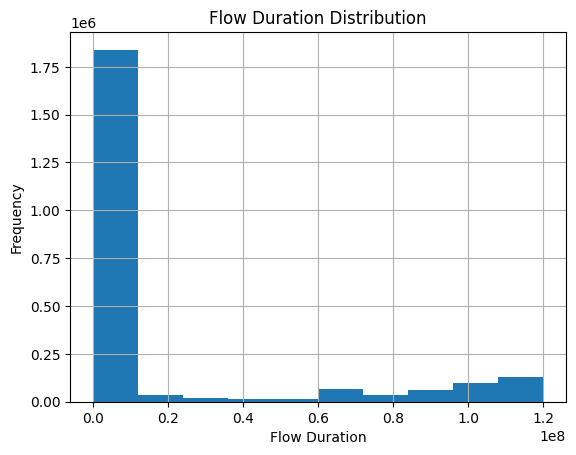

In [ ]:
# ============================================================
# 3.7 FEATURE DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt

df["Flow Duration"].hist()

plt.title("Flow Duration Distribution")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.show()

## 4. Data Preprocessing
### 4.1 Remove Duplicate Records

In [ ]:
# ============================================================
# 4.1 REMOVE DUPLICATES
# ============================================================

before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Records before:", before)
print("Records after:", after)
print("Duplicates removed:", before - after)

Records before: 2313810
Records after: 2231806
Duplicates removed: 82004


### 4.2 Handle Infinite Values

In [ ]:
# ============================================================
# 4.2 HANDLE INFINITE VALUES
# ============================================================

import numpy as np

numeric_columns = df.select_dtypes(include=np.number).columns

print("Infinite values:",
      np.isinf(df[numeric_columns]).sum().sum())

df.replace([np.inf, -np.inf], np.nan, inplace=True)

Infinite values: 0


### 4.3 Handle Missing Values

In [ ]:
# ============================================================
# 4.3 HANDLE MISSING VALUES
# ============================================================

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

print("Missing numerical values handled.")

Missing numerical values handled.


### 4.4 Check Incorrect Values

In [ ]:
# ============================================================
# 4.4 CHECK INCORRECT VALUES
# ============================================================

for column in numeric_columns:
    negative_count = (df[column] < 0).sum()

    if negative_count > 0:
        print(column, ":", negative_count, "negative values")

Flow Duration : 82 negative values
Flow Bytes/s : 53 negative values
Flow Packets/s : 82 negative values
Flow IAT Mean : 82 negative values
Flow IAT Max : 82 negative values
Flow IAT Min : 2801 negative values
Fwd IAT Min : 17 negative values
Fwd Header Length : 35 negative values
Bwd Header Length : 22 negative values
Init Fwd Win Bytes : 909578 negative values
Init Bwd Win Bytes : 1120793 negative values
Fwd Seg Size Min : 35 negative values


### 4.5 Outlier Detection

In [ ]:
# ============================================================
# 4.5 OUTLIER DETECTION
# ============================================================

features = [
    "Flow Duration",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "Flow Bytes/s"
]

for column in features:

    if column in df.columns:

        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)

        IQR = Q3 - Q1

        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR

        outliers = (
            (df[column] < lower) |
            (df[column] > upper)
        ).sum()

        print(column, "-> Outliers:", outliers)

Flow Duration -> Outliers: 462957
Total Fwd Packets -> Outliers: 216137
Total Backward Packets -> Outliers: 209898
Packet Length Mean -> Outliers: 345962
Flow Bytes/s -> Outliers: 486314


### 4.6 Numerical and Categorical Variables

In [ ]:
# ============================================================
# 4.6 NUMERICAL AND CATEGORICAL VARIABLES
# ============================================================

numerical = df.select_dtypes(include=np.number).columns.tolist()
categorical = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical Variables:")
print(numerical)

print("\nCategorical Variables:")
print(categorical)

Numerical Variables:
['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Fla

## 5. Exploratory Data Analysis
### 5.1 Histogram

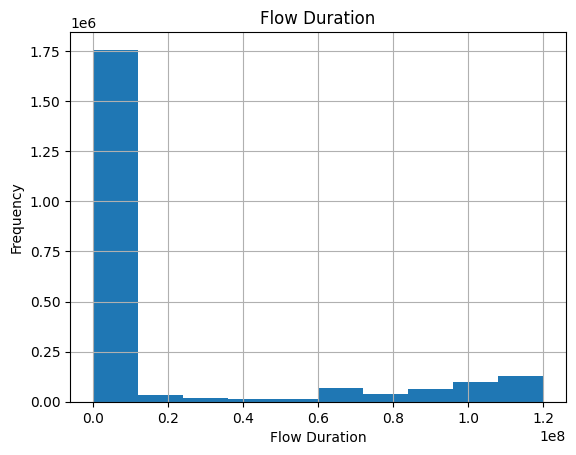

In [ ]:
# ============================================================
# 5.1 HISTOGRAM
# ============================================================

df["Flow Duration"].hist()

plt.title("Flow Duration")
plt.xlabel("Flow Duration")
plt.ylabel("Frequency")
plt.show()

### 5.2 Bar Chart

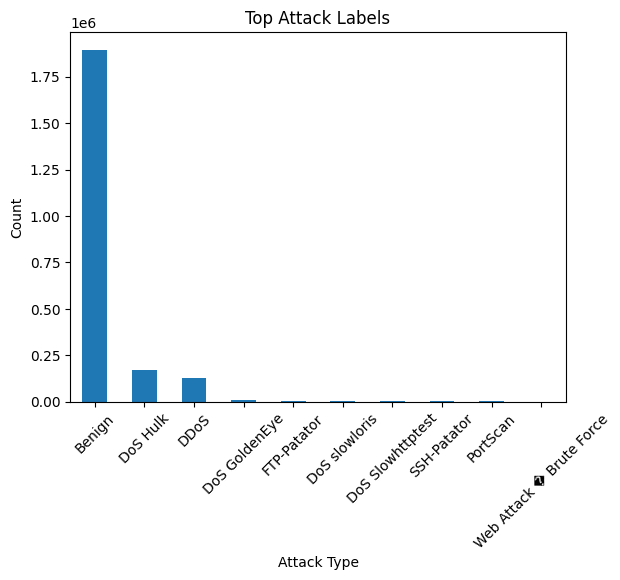

In [ ]:
# ============================================================
# 5.2 BAR CHART
# ============================================================

df["Label"].value_counts().head(10).plot(kind="bar")

plt.title("Top Attack Labels")
plt.xlabel("Attack Type")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

### 5.3 Box Plot

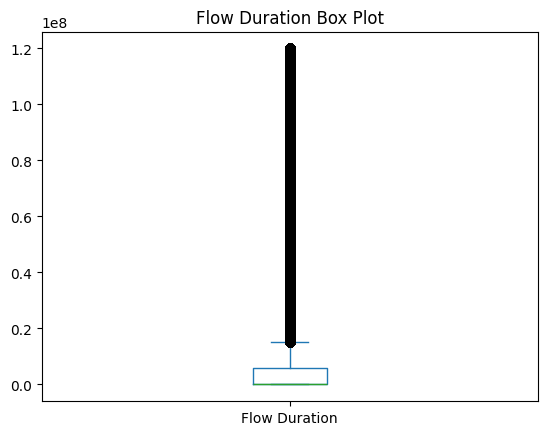

In [ ]:
# ============================================================
# 5.3 BOX PLOT
# ============================================================

df["Flow Duration"].plot(kind="box")

plt.title("Flow Duration Box Plot")
plt.show()

### 5.4 Scatter Plot

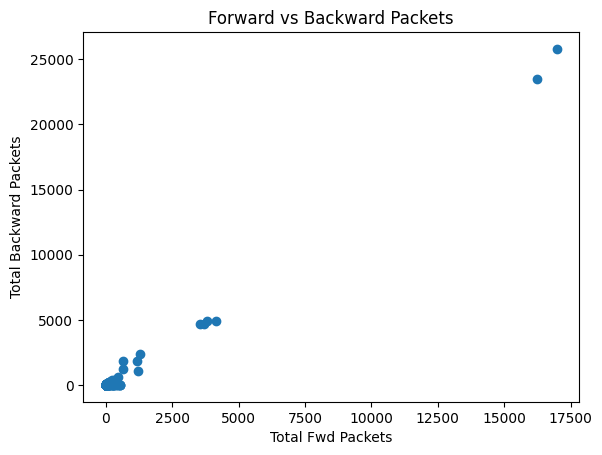

In [ ]:
# ============================================================
# 5.4 SCATTER PLOT
# ============================================================

plt.scatter(
    df["Total Fwd Packets"].head(5000),
    df["Total Backward Packets"].head(5000)
)

plt.title("Forward vs Backward Packets")
plt.xlabel("Total Fwd Packets")
plt.ylabel("Total Backward Packets")
plt.show()

### 5.5 Correlation Heatmap

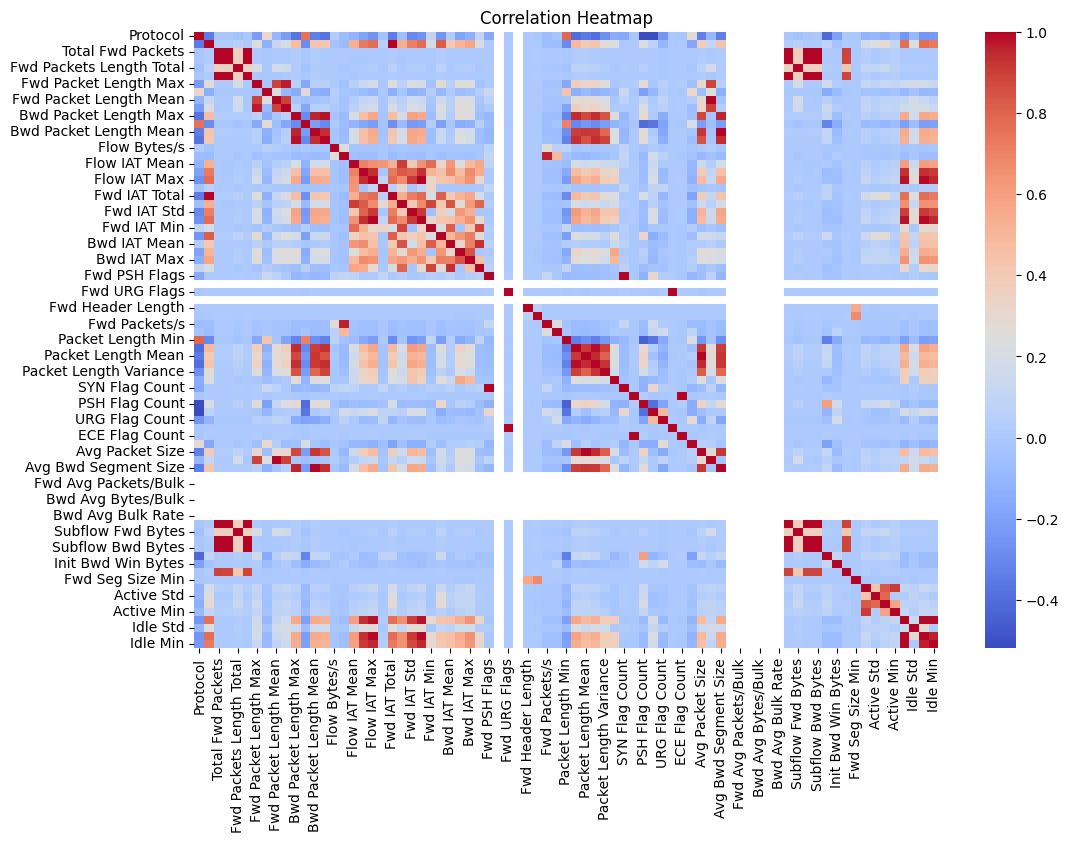

In [ ]:
# ============================================================
# 5.5 CORRELATION HEATMAP
# ============================================================

import seaborn as sns

corr = df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

### 5.6 Count Plot

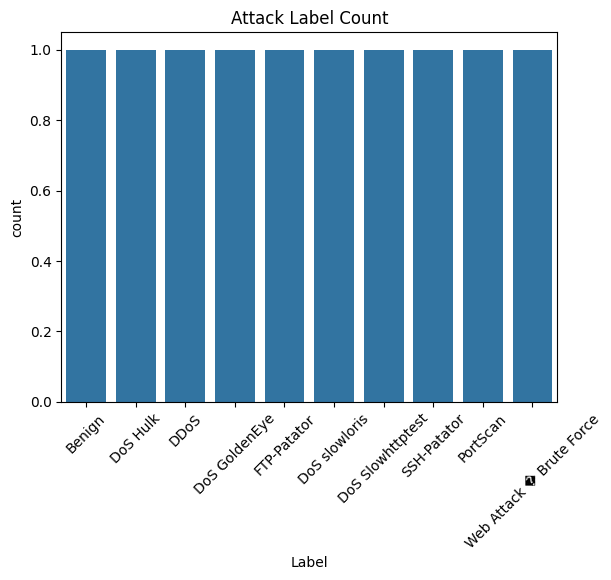

In [ ]:
# ============================================================
# 5.6 COUNT PLOT
# ============================================================

sns.countplot(
    x=df["Label"].value_counts().head(10).index
)

plt.title("Attack Label Count")
plt.xticks(rotation=45)
plt.show()

## 6. Feature Selection / Feature Engineering

In [ ]:
# ============================================================
# 6. FEATURE SELECTION / FEATURE ENGINEERING
# ============================================================

remove_columns = [
    "Flow ID",
    "Source IP",
    "Destination IP",
    "Timestamp",
    "Label"
]

remove_columns = [
    col for col in remove_columns
    if col in df.columns
]

X = df.drop(columns=remove_columns)
y = df["Label"].apply(
    lambda x: 0 if str(x).lower() == "benign" else 1
)

X = pd.get_dummies(X)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(0)

print("Selected features:", X.shape[1])
print("Records:", X.shape[0])

Selected features: 77
Records: 2231806


## 7. Train-Test Split

In [ ]:
# ============================================================
# 7. TRAIN-TEST SPLIT
# ============================================================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1785444
Testing records: 446362


In [ ]:
# ============================================================
# CREATE SMALLER TRAINING DATA FOR FASTER MODEL TRAINING
# ============================================================

from sklearn.model_selection import train_test_split

# Use 100,000 records from the training data
X_train_small, _, y_train_small, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("Original training records:", len(X_train))
print("Training records used for model:", len(X_train_small))
print("Number of features:", X_train_small.shape[1])

Original training records: 1785444
Training records used for model: 100000
Number of features: 77


## 8. Model Building
### 8.1 Random Forest

In [ ]:
# ============================================================
# 8.1 RANDOM FOREST
# ============================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest...")

rf_model.fit(X_train_small, y_train_small)

print("Random Forest training completed!")

Training Random Forest...
Random Forest training completed!


### 8.2 Gradient-Boosted Trees

In [ ]:
# ============================================================
# 8.2 GRADIENT-BOOSTED TREES
# ============================================================

from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=50,
    random_state=42
)

print("Training Gradient-Boosted Trees...")

gb_model.fit(X_train_small, y_train_small)

print("Gradient-Boosted Trees training completed!")

Training Gradient-Boosted Trees...
Gradient-Boosted Trees training completed!


## 9. Model Evaluation
### 9.1 Random Forest Evaluation

In [ ]:
# ============================================================
# 9.1 RANDOM FOREST EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest")

print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred, zero_division=0))
print("Recall   :", recall_score(y_test, rf_pred, zero_division=0))
print("F1-Score :", f1_score(y_test, rf_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest
Accuracy : 0.9978694422912344
Precision: 0.9963195691202873
Recall   : 0.9895243614318192
F1-Score : 0.9929103392749312
ROC-AUC  : 0.9993421550742364

Confusion Matrix:
[[378817    246]
 [   705  66594]]


### 9.2 Gradient-Boosted Trees Evaluation

In [ ]:
# ============================================================
# 9.2 GRADIENT-BOOSTED TREES EVALUATION
# ============================================================

gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

print("Gradient-Boosted Trees")

print("Accuracy :", accuracy_score(y_test, gb_pred))
print("Precision:", precision_score(y_test, gb_pred, zero_division=0))
print("Recall   :", recall_score(y_test, gb_pred, zero_division=0))
print("F1-Score :", f1_score(y_test, gb_pred, zero_division=0))
print("ROC-AUC  :", roc_auc_score(y_test, gb_prob))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

Gradient-Boosted Trees
Accuracy : 0.9927861242668506
Precision: 0.9906283019156853
Recall   : 0.9612475668286304
F1-Score : 0.9757168066846654
ROC-AUC  : 0.9975880040861055

Confusion Matrix:
[[378451    612]
 [  2608  64691]]


### 9.3 Model Comparison

In [ ]:
# ============================================================
# 9.3 MODEL COMPARISON
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Gradient-Boosted Trees"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, gb_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, gb_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, gb_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, gb_prob)
    ]
})

display(results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.997869,0.996320,0.989524,0.992910,0.999342
1,Gradient-Boosted Trees,0.992786,0.990628,0.961248,0.975717,0.997588


## 10. Save the Final Model

In [ ]:
# ============================================================
# 10. SAVE FINAL MODELS
# ============================================================

import joblib

joblib.dump(
    rf_model,
    "/content/random_forest_model.pkl"
)

joblib.dump(
    gb_model,
    "/content/gradient_boosting_model.pkl"
)

joblib.dump(
    X.columns.tolist(),
    "/content/feature_columns.pkl"
)

print("Random Forest model saved!")
print("Gradient-Boosted Trees model saved!")
print("Feature columns saved!")

Random Forest model saved!
Gradient-Boosted Trees model saved!
Feature columns saved!
